<a href="https://colab.research.google.com/github/bcramp/ML/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

HW 6

Title: Dimensionality Reduction, Reconstruction, and Non-Linear Classification on Face Images

Name: Brennen Cramp

Date: 11/1/2026

---

# Task 1: Dataset Loading and Dimensionality Inspection

The following code cell imports the Olivetti Faces dataset from the Scikit-Learn Dataset repository and inspects the dimensionality of the dataset.
- This data is extracted into features,  target, and images where dimensionality inspection metrics (total number of samples, unique target subjects, and feature dimensions) are calculated and printed.
- A plot with a 4x5 grid of sample faces labeled with their subject IDs (randomly selected) and they were displayed to show correct fetching of the data.

--- Dataset Dimensionality Inspection ---
Total number of samples: 400
Unique target subjects: 40
Feature dimensions: 4096 (Flattened 64x64 pixels)
-----------------------------------------



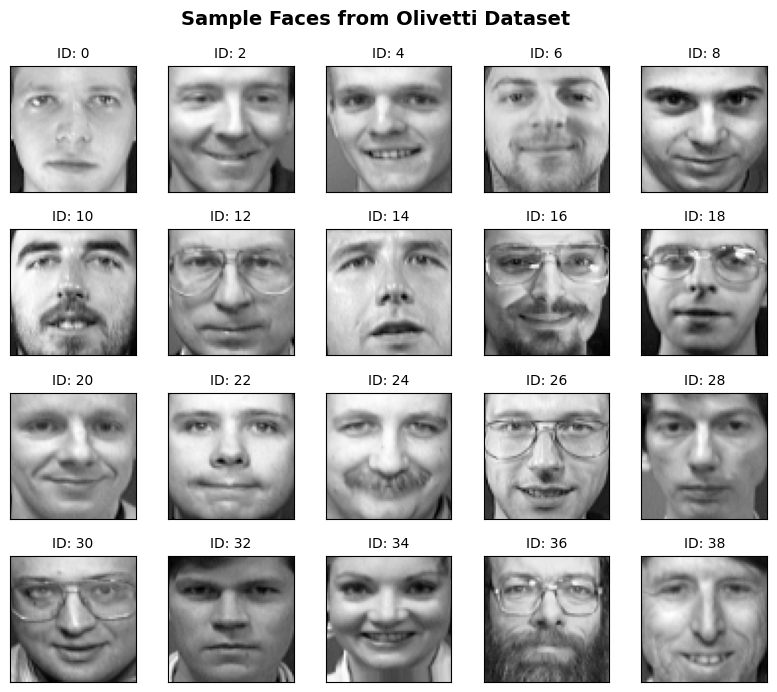

In [21]:
# Import Pandas for handling tabular data
# Import NumPy for handling scientific computing and math operations
# Import the Matplotlib.pyplot for handling visualization tools
# Import the Scikit-Learn's fetch_olivetti_faces to get the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

# Grab the Olivetti Faces dataset and set shuffle=False to load the dataset in a structured order and set
# random_state to ensure a good mix of subjects in the initial inspection
seed = 100
faces = fetch_olivetti_faces(shuffle=False, random_state=seed)

# Extract the features and target
X = faces.data
y = faces.target
images = faces.images

# Print dimensionality inspection metrics
n_samples, n_features = X.shape
unique_subjects = len(np.unique(y))
image_shape = images[0].shape

print("--- Dataset Dimensionality Inspection ---")
print(f"Total number of samples: {n_samples}")
print(f"Unique target subjects: {unique_subjects}")
print(f"Feature dimensions: {n_features} (Flattened {image_shape[0]}x{image_shape[1]} pixels)")
print("-----------------------------------------\n")

# Plot the 4x5 grid of sample faces
fig, axes = plt.subplots(4, 5, figsize=(10, 8), subplot_kw={'xticks':[], 'yticks':[]}, gridspec_kw=dict(hspace=0.3, wspace=0.1))

for i, ax in enumerate(axes.flat):
    # Select images spread across the dataset to show different individuals
    idx = i*20
    ax.imshow(images[idx], cmap='gray')
    ax.set_title(f"ID: {y[idx]}", fontsize=10)

plt.suptitle("Sample Faces from Olivetti Dataset", fontsize=14, fontweight='bold', y=0.95)
plt.show()

# Task 2: Cumulative Explained Variance & Elbow Plot

The following code cell will fit a full PCA model to the entire dataset. This allows mapping out the individual and cumulative explained variance ratios and calculate the exact thresholds needed for the downstream pipelines.
- Fits a full PCA model on the dataset.
- Determines and prints the exact number of components required to preserve 90%, 95%, and 99% of the cumulative variance.
- Plots both the individual explained variance ratio and the cumulative explained variance curve versus the number of principal components.

--- Task 2: Cumulative Explained Variance & Elbow Plot ---
--- Variance Threshold Thresholds ---
90% cumulative variance preserved: 66 components
95% cumulative variance preserved: 123 components
99% cumulative variance preserved: 260 components
-------------------------------------



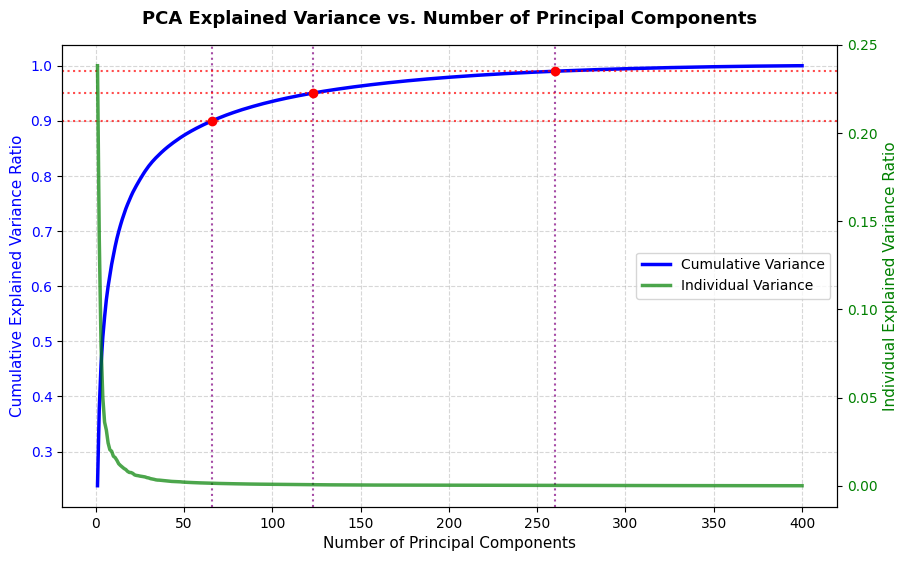

In [22]:
# Import Scikit-Learn's PCA library
from sklearn.decomposition import PCA

# Task 2: Cumulative Explained Variance & Elbow Plot
print("--- Task 2: Cumulative Explained Variance & Elbow Plot ---")

# Fit a full PCA model on the entire dataset
pca_full = PCA(random_state=seed)
pca_full.fit(X)

# Extract individual and cumulative explained variance ratios
indiv_var = pca_full.explained_variance_ratio_
cumul_var = np.cumsum(indiv_var)

# Determine the exact number of components required for 90%, 95%, and 99% variance
thresholds = [0.90, 0.95, 0.99]
components_needed = {}

print("--- Variance Threshold Thresholds ---")
for t in thresholds:
    # np.argmax returns the first index where the condition is True
    # I will add +1 for the count
    n_comps = np.argmax(cumul_var >= t) + 1
    components_needed[t] = n_comps
    print(f"{int(t*100)}% cumulative variance preserved: {n_comps} components")
print("-------------------------------------\n")

# Styling for the combined plot
# Plot individual and cumulative variance (elbow plot)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Primary y-axis (cumulative explained variance)
color1 = 'blue'
ax1.set_xlabel('Number of Principal Components', fontsize=11)
ax1.set_ylabel('Cumulative Explained Variance Ratio', color=color1, fontsize=11)
line1 = ax1.plot(range(1, len(cumul_var) + 1), cumul_var, color=color1, linewidth=2.5, label='Cumulative Variance')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.5)

# Add horizontal marker lines for target thresholds
for t, n_comps in components_needed.items():
    ax1.axhline(y=t, color='red', linestyle=':', alpha=0.7)
    ax1.axvline(x=n_comps, color='purple', linestyle=':', alpha=0.7)
    ax1.plot(n_comps, t, 'ro') # I want to add a red dot at intersections

# Secondary y-axis (individual explained variance)
ax2 = ax1.twinx()
color2 = 'green'
ax2.set_ylabel('Individual Explained Variance Ratio', color=color2, fontsize=11)
line2 = ax2.plot(range(1, len(indiv_var) + 1), indiv_var, color=color2, linewidth=2.5, alpha=0.7, label='Individual Variance')
ax2.tick_params(axis='y', labelcolor=color2)

# Sets up the Legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right')

plt.title("PCA Explained Variance vs. Number of Principal Components", fontsize=13, fontweight='bold', pad=15)
plt.show()

# Task 3: Image Compression and Reconstruction Analysis

The following code cell picks 5 representative facial images and compresses them down to varying values of k (10, 50, 100, 200, 300). A matrix grid will be displayed matching original images with their compressed twins and tracks how Mean Squared Error (MSE) drops as k gets larger.
- Selects 5 representative facial images {0, 80, 160, 240, 320}.
- Compresses and reconstructs them using PCA with varying numbers of components; e.g., k in {10, 50, 100, 200, 300}.
- Plots a grid comparing the original images against their reconstructions across each component threshold, and compute/plot the Mean Squared Error (MSE) between original and reconstructed faces as a function of k.

--- Task 3: Image Compression and Reconstruction Analysis ---


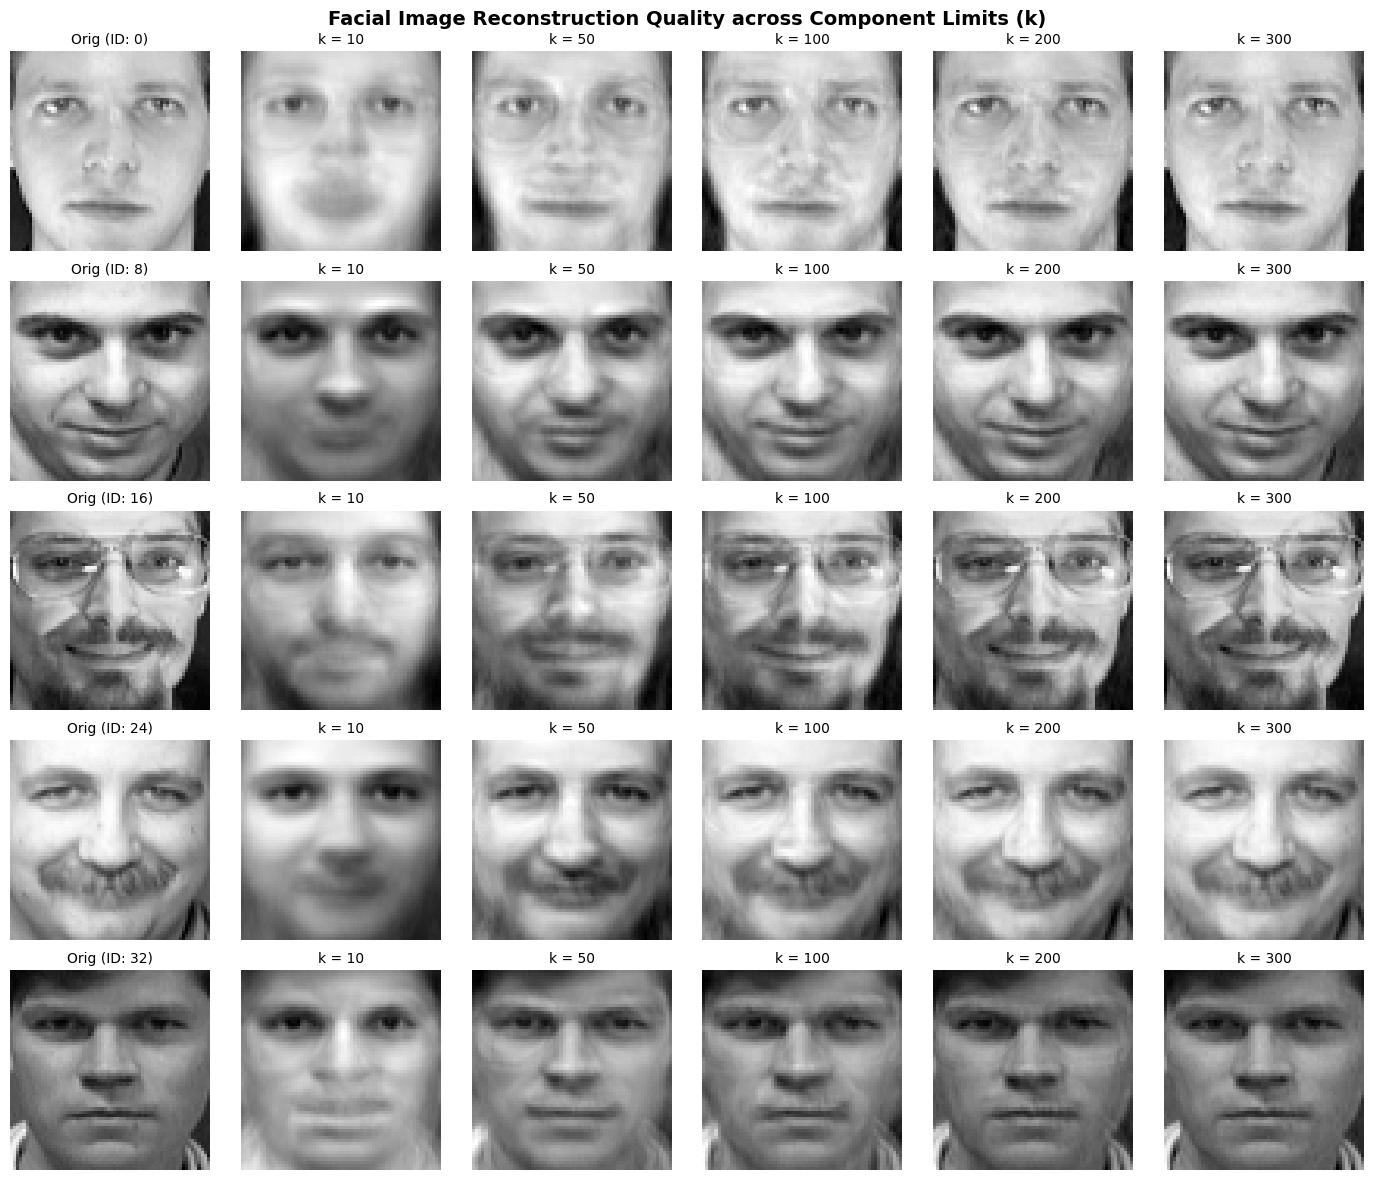

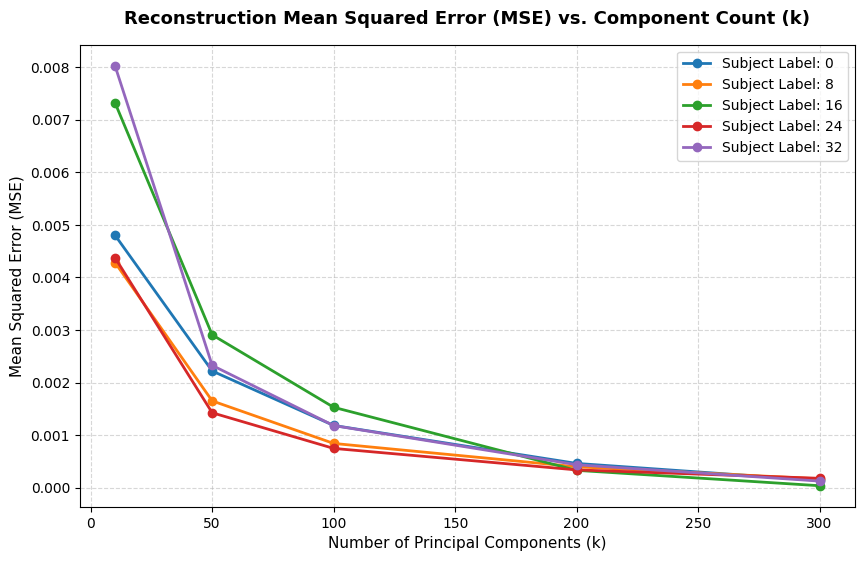

In [23]:
# Import Scikit-Learn's SimpleImputer to handle missing entries
from sklearn.impute import SimpleImputer

# Task 3: Image Compression and Reconstruction Analysis
print("--- Task 3: Image Compression and Reconstruction Analysis ---")

# Select 5 representative facial images
sample_indices = [0, 80, 160, 240, 320]
k_values = [10, 50, 100, 200, 300]

# Create lists/dictionaries to track reconstructions and MSE calcs
reconstructed_images = {k: [] for k in k_values}
mse_results = {idx: [] for idx in sample_indices}

# Process each k-value systematically
for k in k_values:
    # Initialize PCA with k-components
    pca_k = PCA(n_components=k, random_state=seed)

    # Fits on entire dataset and transforms the selected sample images
    X_reduced = pca_k.fit_transform(X)
    X_recovered = pca_k.inverse_transform(X_reduced)

    # Extract and store reconstructions for the 5 specific faces
    for idx in sample_indices:
        # Reshapes the flattened 4096-dimensional back to the 64x64 grid
        reconstructed_face = X_recovered[idx].reshape(64, 64)
        reconstructed_images[k].append(reconstructed_face)

        # Calc MSE between orig and reconstructed images
        original_face = images[idx]
        mse = np.mean((original_face - reconstructed_face) ** 2)
        mse_results[idx].append(mse)

# Styling for the plot for the orig vs reconstructins image grid
fig, axes = plt.subplots(5, 6, figsize=(14, 12))

for i, idx in enumerate(sample_indices):
    # Plot original image in the first column
    axes[i, 0].imshow(images[idx], cmap='gray')
    axes[i, 0].set_title(f"Orig (ID: {y[idx]})", fontsize=10)
    axes[i, 0].axis('off')

    # Plot reconstructions for each k-threshold across columns
    for j, k in enumerate(k_values):
        axes[i, j + 1].imshow(reconstructed_images[k][i], cmap='gray')
        axes[i, j + 1].set_title(f"k = {k}", fontsize=10)
        axes[i, j + 1].axis('off')

plt.suptitle("Facial Image Reconstruction Quality across Component Limits (k)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# Styling for the MSE plot
plt.figure(figsize=(10, 6))
for idx in sample_indices:
    plt.plot(k_values, mse_results[idx], marker='o', linewidth=2, label=f"Subject Label: {y[idx]}")

plt.title("Reconstruction Mean Squared Error (MSE) vs. Component Count (k)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Number of Principal Components (k)", fontsize=11)
plt.ylabel("Mean Squared Error (MSE)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# Task 4: Visualization of "Eigenfaces"

The following code cell extracts the underlying eigenvectors from the full PCA model. Then, the first 15 components will be extracted and reshaped back into 64x64 matrices and then displayed alongside their individual explained variance percentages.
- Extracts the principal components (eigenvectors) from the fitted PCA model.
- Reshapes the first 15 principal components back into 64x64 grids and visualizes them in a 3x5 plot grid ("Eigenfaces"). Each plot will also be annotated with the percentage of total variance explained by that specific component.

--- Task 4: Visualization of "Eigenfaces" ---


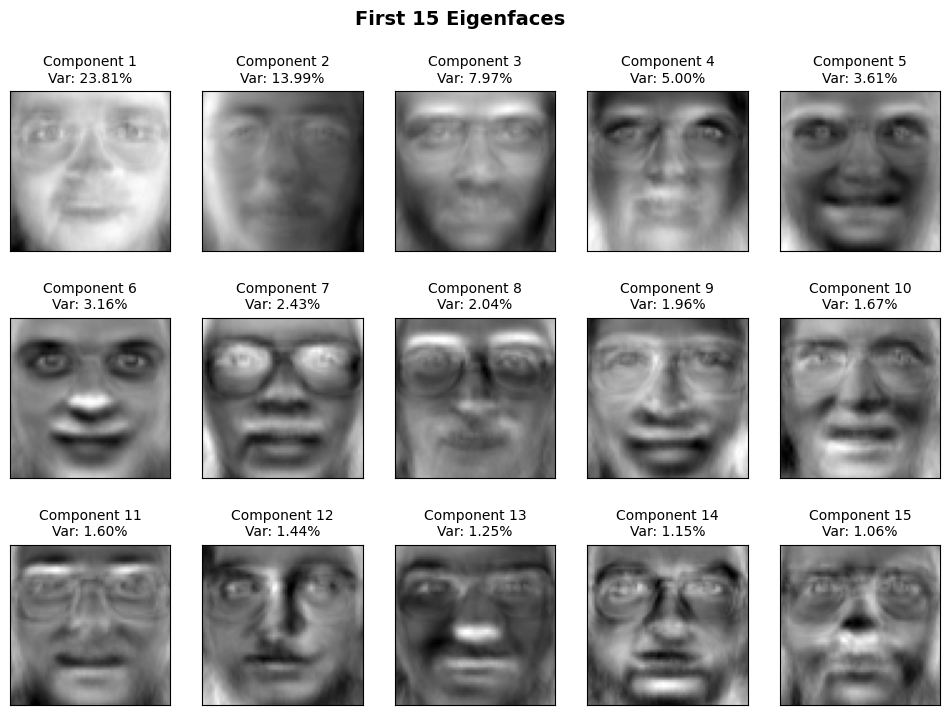

In [24]:
# Task 4: Visualization of "Eigenfaces"
print("--- Task 4: Visualization of \"Eigenfaces\" ---")

# Extract the components (eigenvectors) from the full PCA model
eigenfaces = pca_full.components_

# Styling for the plot
# Creates a 3x5 grid to display the first 15 components
fig, axes = plt.subplots(3, 5, figsize=(12, 8), subplot_kw={'xticks': [], 'yticks': []}, gridspec_kw=dict(hspace=0.4, wspace=0.2))

for i, ax in enumerate(axes.flat):
    # Reshape the i-th eigenvector from 4096 dimensions back into a 64x64 grid
    eigenface_matrix = eigenfaces[i].reshape(64, 64)

    # Calc the % of total variance explained by the current component
    var_perc = indiv_var[i] * 100

    # Plots using a grayscale mapping
    ax.imshow(eigenface_matrix, cmap='gray')
    ax.set_title(f"Component {i+1}\nVar: {var_perc:.2f}%", fontsize=10)

plt.suptitle("First 15 Eigenfaces", fontsize=14, fontweight='bold', y=0.98)
plt.show()

# Task 5: Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model)

The following code cell evaluates how dimensionality reduction impacts machine learning performance by spliting the data using a stratified 80/20 train/test split. Then, trains two separate LogisticRegression models - one on the raw 4096 features and another on PCA-reduced features capturing 95% variance. Both accuracy and training time are tracked and displays the trade-offs using a dual-axis bar plot.
- Performs a stratified train/test split (80/20).
- Trains a LogisticRegression classifier on: the raw 4,096-dimensional feature vectors AND the PCA-reduced feature vectors using the 95% variance threshold fitted strictly on the training set.
- Evaluates and prints the test accuracy and training time for both, and visualizes the performance comparison in a dual-axis bar plot - "Logistic Regression Performance: Raw vs. PCA Features (Accuracy vs. Training Time)".

--- Task 5: Classification Baseline — Raw vs. PCA-Reduced Features ---
--- Raw Features Configuration ---
Features: 4096
Training Time: 0.9600 seconds
Test Accuracy: 96.25%
----------------------------------

--- PCA-Reduced Configuration (95% Variance) ---
Features: 123
Training Time: 0.0197 seconds
Test Accuracy: 96.25%
----------------------------------



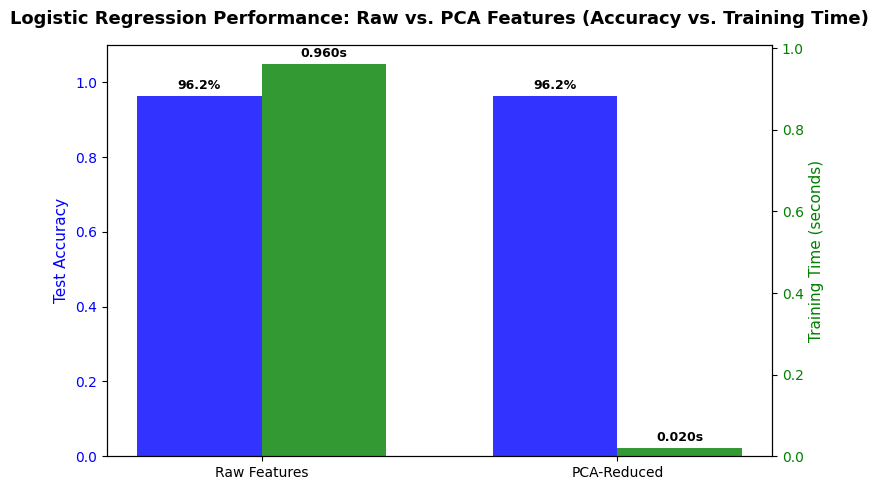

In [25]:
# Imports time to track training time
# Imports needed functionalities from Scikit-Learn
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Task 5: Classification Baseline — Raw vs. PCA-Reduced Features
print("--- Task 5: Classification Baseline — Raw vs. PCA-Reduced Features ---")

# Splits the data using an 80/20 split (20% for test) and I will also set the random seed to be 100.
# I set stratify along the target to keep balance identical in both of my sets.
test_ratio = 0.2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_ratio, random_state=seed, stratify=y
)

# Create the "Baseline Model 1: Logistic Regression on Raw Features"
# I also added scaling for stable/faster convergence of linear models
scaler_raw = StandardScaler()
X_train_raw_scaled = scaler_raw.fit_transform(X_train)
X_test_raw_scaled = scaler_raw.transform(X_test)

# Create LR model for raw
lr_raw = LogisticRegression(max_iter=10000, random_state=seed)

# Fits the raw LR model exclusively on the scaled train set
start_time = time.time()
lr_raw.fit(X_train_raw_scaled, y_train)
time_raw = time.time() - start_time
acc_raw = lr_raw.score(X_test_raw_scaled, y_test)

# Print results for raw features
print("--- Raw Features Configuration ---")
print(f"Features: {X_train.shape[1]}")
print(f"Training Time: {time_raw:.4f} seconds")
print(f"Test Accuracy: {acc_raw * 100:.2f}%")
print("----------------------------------\n")

# Create the "Baseline Model 2: Logistic Regression on PCA-Reduced Features (95% Variance)"
# Finds the exact component threshold from the dict mapping from Task 2
n_comps_95 = components_needed[0.95]

pca_95 = PCA(n_components=n_comps_95, random_state=seed)
X_train_pca = pca_95.fit_transform(X_train)
X_test_pca = pca_95.transform(X_test)

# Scales PCA features to optimize LR convergence
scaler_pca = StandardScaler()
X_train_pca_scaled = scaler_pca.fit_transform(X_train_pca)
X_test_pca_scaled = scaler_pca.transform(X_test_pca)

# Create LR model for PCA
lr_pca = LogisticRegression(max_iter=10000, random_state=seed)

# Fits the PCA LR model exclusively on the scaled train set
start_time = time.time()
lr_pca.fit(X_train_pca_scaled, y_train)
time_pca = time.time() - start_time
acc_pca = lr_pca.score(X_test_pca_scaled, y_test)

# Print results for PCA
print("--- PCA-Reduced Configuration (95% Variance) ---")
print(f"Features: {n_comps_95}")
print(f"Training Time: {time_pca:.4f} seconds")
print(f"Test Accuracy: {acc_pca * 100:.2f}%")
print("----------------------------------\n")

# Creates the dual-axis bar plot
models = ['Raw Features', 'PCA-Reduced']
accuracies = [acc_raw, acc_pca]
times = [time_raw, time_pca]

x = np.arange(len(models))
width = 0.35

# Styling for the plot
fig, ax1 = plt.subplots(figsize=(8, 5))

# Primary axis (test accuracy)
color_acc = 'blue'
ax1.set_ylabel('Test Accuracy', color=color_acc, fontsize=11)
bars_acc = ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color_acc, alpha=0.8)
ax1.set_ylim(0, 1.1)
ax1.tick_params(axis='y', labelcolor=color_acc)
ax1.set_xticks(x)
ax1.set_xticklabels(models)

# Secondary axis (training time)
ax2 = ax1.twinx()
color_time = 'green'
ax2.set_ylabel('Training Time (seconds)', color=color_time, fontsize=11)
bars_time = ax2.bar(x + width/2, times, width, label='Training Time', color=color_time, alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color_time)

# Creates a function to adds value labels on top of the bars
# IMPORTANT NOTE: I had to Google this helper method since I was having trouble with formatting!
def autolabel(bars, ax, is_percentage=False):
    for bar in bars:
        height = bar.get_height()
        label = f"{height*100:.1f}%" if is_percentage else f"{height:.3f}s"
        ax.annotate(label,
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), # Adds 3 points vertical offset
                    textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

# Adds labels
autolabel(bars_acc, ax1, is_percentage=True)
autolabel(bars_time, ax2, is_percentage=False)

plt.title("Logistic Regression Performance: Raw vs. PCA Features (Accuracy vs. Training Time)", fontsize=13, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

# Task 6: Non-Linear Classification (Kernel SVM)

The following code cell instantiates and trains a Support Vector Classifier (SVC) with a Radial Basis Function (RBF) kernel on the same 95% variance PCA-reduced features. The performance metrics will also be recorded and a plot will be generated for the classification breakdown comparing its predictions directly against the linear baseline.
- Trains an SVC with an RBF kernel on the PCA-reduced features (95% variance).
- Records the training time and test accuracy.
- Prints classification summaries comparing its predictions against the linear baseline.
- Plots confusion matrices comparing its predictions against the linear baseline.

--- Task 6: Non-Linear Classification (Kernel SVM) ---
--- Kernel SVM (RBF) on PCA Features ---
Training Time: 0.0232 seconds
Test Accuracy: 95.00%
----------------------------------

--- Linear Baseline (PCA Logistic Regression) Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2
           2       1.00      0.50      0.67         2
           3       0.67      1.00      0.80         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         2
          12       0.50      0.50      0.

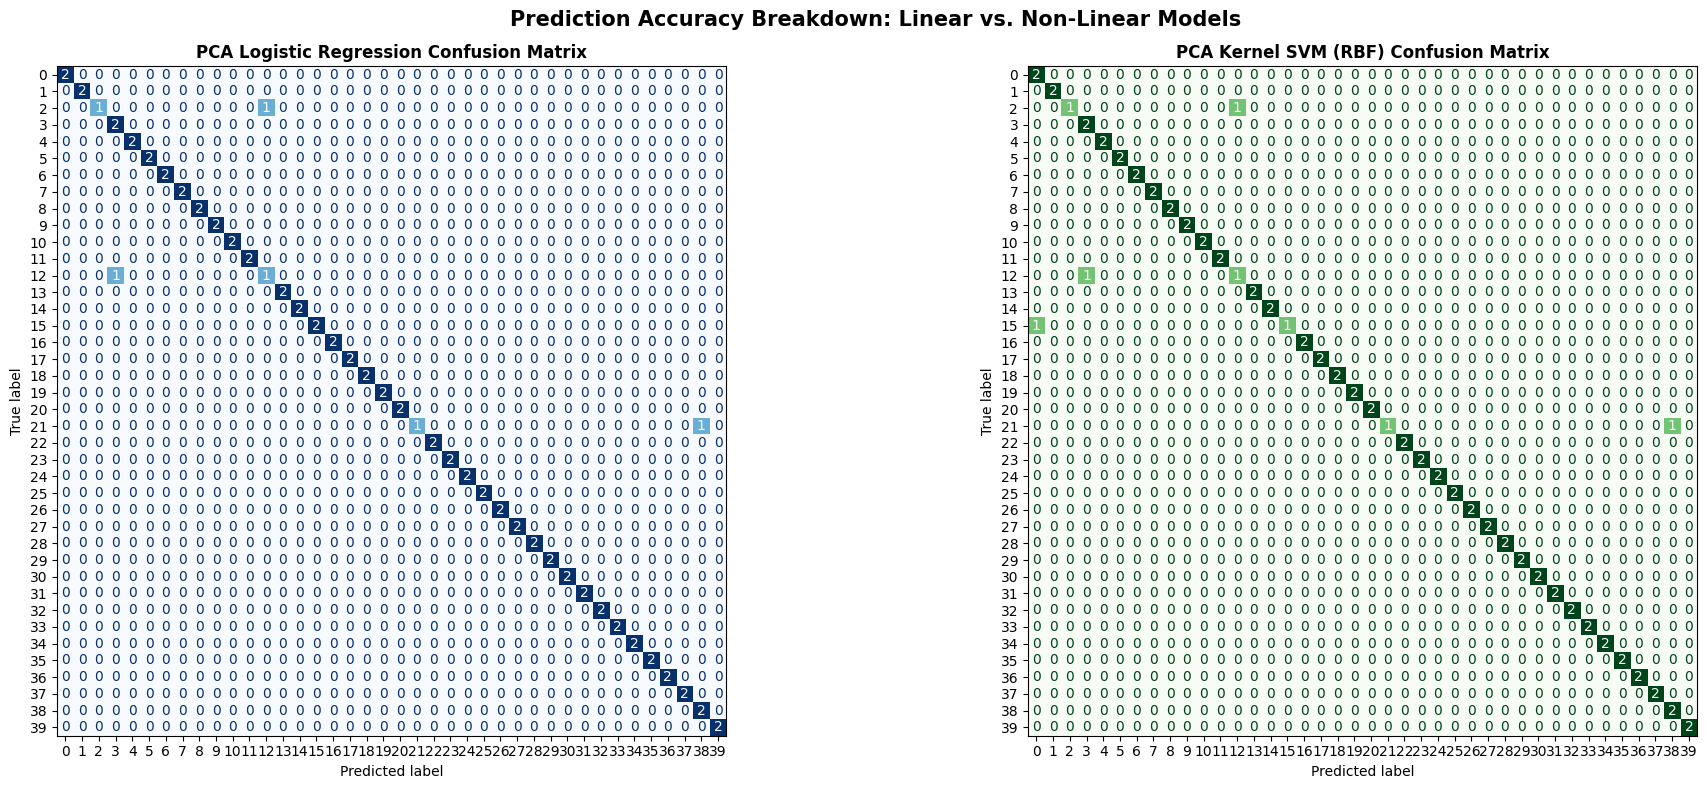

In [26]:
# Import needed functionalities from Scikit-Learn
from sklearn.svm import SVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Task 6: Non-Linear Classification (Kernel SVM)
print("--- Task 6: Non-Linear Classification (Kernel SVM) ---")

# Instantiates the SVC with RBF Kernel, C=1.0, and gamma='scale'
svc_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=seed)

# Fits the SVC model exclusively on the scaled train set from Task 5 for PCA
start_time = time.time()
svc_rbf.fit(X_train_pca_scaled, y_train)
time_svc = time.time() - start_time
acc_svc = svc_rbf.score(X_test_pca_scaled, y_test)

# Print results for PCA
print("--- Kernel SVM (RBF) on PCA Features ---")
print(f"Training Time: {time_svc:.4f} seconds")
print(f"Test Accuracy: {acc_svc * 100:.2f}%")
print("----------------------------------\n")

# Print the classification reports
print("--- Linear Baseline (PCA Logistic Regression) Classification Report ---")
y_pred_lr = lr_pca.predict(X_test_pca_scaled)
print(classification_report(y_test, y_pred_lr, zero_division=0))
print("-----------------------------------------------------------------------")

print("\n--- Non-Linear Baseline (Kernel SVM) Classification Report ---")
y_pred_svc = svc_rbf.predict(X_test_pca_scaled)
print(classification_report(y_test, y_pred_svc, zero_division=0))
print("-----------------------------------------------------------------------")

# Styling for the plot
# Plot the confusion matrices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, ax=ax1, cmap='Blues', colorbar=False)
ax1.set_title("PCA Logistic Regression Confusion Matrix", fontsize=12, fontweight='bold')

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svc, ax=ax2, cmap='Greens', colorbar=False)
ax2.set_title("PCA Kernel SVM (RBF) Confusion Matrix", fontsize=12, fontweight='bold')

plt.suptitle("Prediction Accuracy Breakdown: Linear vs. Non-Linear Models", fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# Task 7: Ensemble Classification on PCA Features

The following code cell instantiates and trains a VotingClassifier using soft voting for an ensemble model, combining the predictions of multiple estimators to improve generalization and stability. The performance for each model will be printed to the console to compare.
- Constructs a VotingClassifier (soft voting) combining a Polynomial Kernel SVM (degree=2), an RBF Kernel SVM, and a RandomForestClassifier (n_estimators=100).
- Trains the ensemble on the PCA-reduced features, recording training time and accuracy, and compares its performance against the single linear and non-linear models.

In [27]:
# Import needed functionalities from Scikit-Learn
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import RandomForestClassifier

# Task 7: Ensemble Classification on PCA Features
print("--- Task 7: Ensemble Classification on PCA Features ---")

# Defines the individual base models/estimators and I set the probability=True for the svm_model which is required for soft voting
svc_poly = SVC(kernel='poly', degree=2, probability=True, random_state=seed)
svc_rbf_ens = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=seed)
rf_model = RandomForestClassifier(n_estimators=100, random_state=seed)

# Construct the classifier using soft voting
ensemble_classifier = VotingClassifier(
    estimators=[
        ('poly_svm', svc_poly),
        ('rbf_svm', svc_rbf_ens),
        ('rf', rf_model)
    ],
    voting='soft'
)

# Fits the enemble exclusively on the scaled train set from Task 5 for PCA
start_time = time.time()
ensemble_classifier.fit(X_train_pca_scaled, y_train)
time_ensemble = time.time() - start_time
acc_ensemble = ensemble_classifier.score(X_test_pca_scaled, y_test)

# Print results for PCA
print("--- Soft Voting Ensemble on PCA Features ---")
print(f"Training Time: {time_ensemble:.4f} seconds")
print(f"Test Accuracy: {acc_ensemble * 100:.2f}%")
print("----------------------------------\n")

# Compare performance against previous single models
print("--- Performance Comparison Between Models ---")
print(f"Logistic Regression (PCA): Test Accuracy = {acc_pca*100:.2f}%, Training Time = {time_pca:.4f}s")
print(f"Kernel SVM (RBF - PCA): Test Accuracy = {acc_svc*100:.2f}%, Training Time = {time_svc:.4f}s")
print(f"Soft Voting Ensemble: Test Accuracy = {acc_ensemble*100:.2f}%, Training Time = {time_ensemble:.4f}s")
print("----------------------------------\n")

--- Task 7: Ensemble Classification on PCA Features ---
--- Soft Voting Ensemble on PCA Features ---
Training Time: 0.7579 seconds
Test Accuracy: 95.00%
----------------------------------

--- Performance Comparison Between Models ---
Logistic Regression (PCA): Test Accuracy = 96.25%, Training Time = 0.0197s
Kernel SVM (RBF - PCA): Test Accuracy = 95.00%, Training Time = 0.0232s
Soft Voting Ensemble: Test Accuracy = 95.00%, Training Time = 0.7579s
----------------------------------



# Task 8: Comprehensive Comparative Evaluation

The following code cell will combine the metrics from all four experiments into a single, clean visual plot. This plot will display 'Test Accuracy' on the primary left y-axis and 'Training Time' in seconds on the secondary right y-axis.
- Creates a single summary bar plot comparing Accuracy (primary y-axis) and Training Time in seconds (secondary y-axis) across all four model configurations:
  - Logistic Regression (Raw Features)
  - Logistic Regression (PCA-Reduced)
  - Support Vector Classifier with RBF Kernel (PCA-Reduced)
  - Soft Voting Ensemble (PCA-Reduced)

--- Task 8: Comprehensive Comparative Evaluation ---


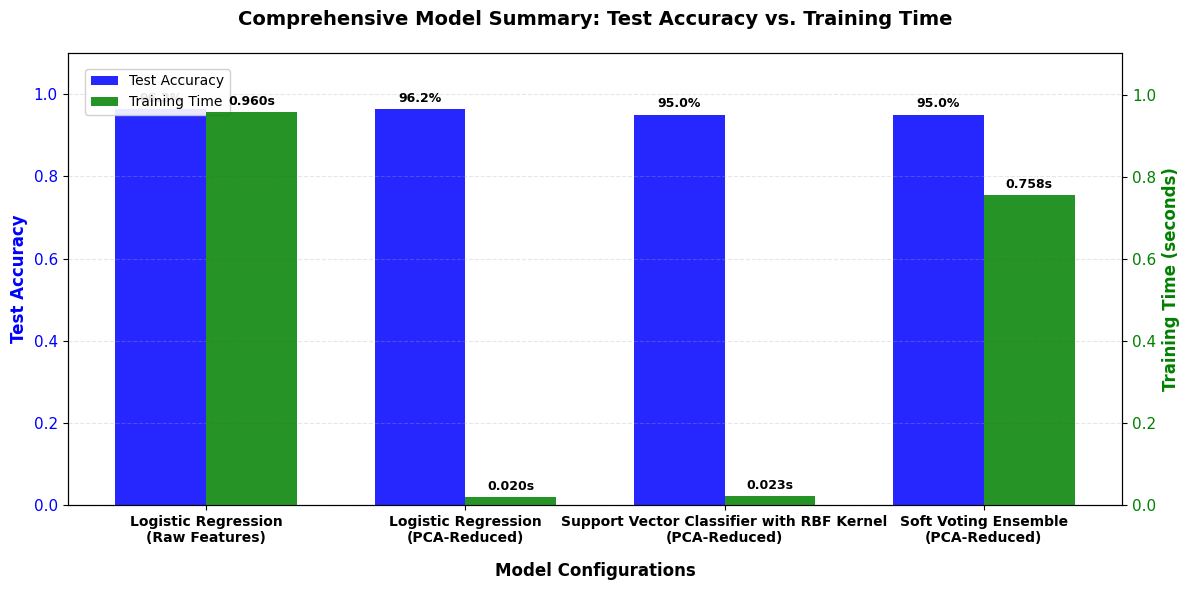

In [28]:
# Task 8: Comprehensive Comparative Evaluation
print("--- Task 8: Comprehensive Comparative Evaluation ---")

# Combines the data from all four model configurations
model_names = [
    'Logistic Regression\n(Raw Features)',
    'Logistic Regression\n(PCA-Reduced)',
    'Support Vector Classifier with RBF Kernel\n(PCA-Reduced)',
    'Soft Voting Ensemble\n(PCA-Reduced)'
]

final_accuracies = [acc_raw, acc_pca, acc_svc, acc_ensemble]
final_times = [time_raw, time_pca, time_svc, time_ensemble]

# Styling for the combined plot
# Sets up the figure and primary axis (Test Accuracy)
fig, ax1 = plt.subplots(figsize=(12, 6))
x_indices = np.arange(len(model_names))
bar_width = 0.35

color_accuracy = 'blue'
ax1.set_xlabel('Model Configurations', fontsize=12, fontweight='bold', labelpad=12)
ax1.set_ylabel('Test Accuracy', color=color_accuracy, fontsize=12, fontweight='bold')
bars_accuracy = ax1.bar(x_indices - bar_width/2, final_accuracies, bar_width, label='Test Accuracy', color=color_accuracy, alpha=0.85)

ax1.set_ylim(0, 1.1)
ax1.tick_params(axis='y', labelcolor=color_accuracy, labelsize=11)
ax1.set_xticks(x_indices)
ax1.set_xticklabels(model_names, fontsize=10, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.3, axis='y')

# Sets up the secondary axis (Training Time)
ax2 = ax1.twinx()
color_time = 'green'
ax2.set_ylabel('Training Time (seconds)', color=color_time, fontsize=12, fontweight='bold')
bars_time = ax2.bar(x_indices + bar_width/2, final_times, bar_width, label='Training Time', color=color_time, alpha=0.85)

ax2.tick_params(axis='y', labelcolor=color_time, labelsize=11)

# Adjusts the right y-axis limit dynamically to avoid labels from overlapping
ax2.set_ylim(0, max(final_times) * 1.15)

# Adds labels
# IMPORTANT NOTE: This is the same method from Task 5 that I had to Google for help!
autolabel(bars_accuracy, ax1, is_percentage=True)
autolabel(bars_time, ax2, is_percentage=False)

# Sets up the Legend
combined_lines = [bars_accuracy, bars_time]
combined_labels = [bar.get_label() for bar in combined_lines]
ax1.legend(combined_lines, combined_labels, loc='upper left', bbox_to_anchor=(0.01, 0.98), framealpha=0.9)

plt.title("Comprehensive Model Summary: Test Accuracy vs. Training Time", fontsize=14, fontweight='bold', pad=20)
fig.tight_layout()
plt.show()